In [1]:
!pip install xgboost



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

In [3]:
df = pd.read_csv(r"D:\anshs\Project 1new\data\exam_marks.csv")

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group D,some college,standard,completed,59,70,78
1,male,group D,associate's degree,standard,none,96,93,87
2,female,group D,some college,free/reduced,none,57,76,77
3,male,group B,some college,free/reduced,none,70,70,63
4,female,group D,associate's degree,standard,none,83,85,86


In [5]:
X = df.drop(columns=['math score'])

In [6]:
X.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group D,some college,standard,completed,70,78
1,male,group D,associate's degree,standard,none,93,87
2,female,group D,some college,free/reduced,none,76,77
3,male,group B,some college,free/reduced,none,70,63
4,female,group D,associate's degree,standard,none,85,86


In [7]:
print("Categories in 'gender' variable:     ",end=" " )
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:  ",end=" ")
print(df['race/ethnicity'].unique())

print("Categories in'parental level of education' variable:",end=" " )
print(df['parental level of education'].unique())

print("Categories in 'lunch' variable:     ",end=" " )
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable:     ",end=" " )
print(df['test preparation course'].unique())

Categories in 'gender' variable:      <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:   <StringArray>
['group D', 'group B', 'group C', 'group E', 'group A']
Length: 5, dtype: str
Categories in'parental level of education' variable: <StringArray>
[      'some college', 'associate's degree',   'some high school',
  'bachelor's degree',    'master's degree',        'high school']
Length: 6, dtype: str
Categories in 'lunch' variable:      <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable:      <StringArray>
['completed', 'none']
Length: 2, dtype: str


In [8]:
y = df['math score']

In [9]:
y

0      59
1      96
2      57
3      70
4      83
       ..
995    77
996    80
997    67
998    80
999    58
Name: math score, Length: 1000, dtype: int64

In [10]:
# Create Column Transformer with 3 types of transformers
num_features = X.select_dtypes(exclude = 'object').columns
cat_features = X.select_dtypes(include = 'object').columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_tranformer = StandardScaler()
oh_tranformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [("OneHotEncoder", oh_tranformer, cat_features),
     ('StandardScaler', numeric_tranformer, num_features),
     ]
)

C:\Users\anshs\AppData\Local\Temp\ipykernel_10684\1442711930.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X.select_dtypes(include = 'object').columns


In [11]:
X = preprocessor.fit_transform(X)

In [12]:
X.shape

(1000, 19)

In [13]:
# separate dataset into train and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
X_train.shape, X_test.shape

((800, 19), (200, 19))

In [14]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [15]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGB Regressor": XGBRegressor(),
    "CatBoost Regressor": CatBoostRegressor(verbose = False),
    "AdaBoost Regressor": AdaBoostRegressor(),
}
model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate train and test dataset
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print("Model performance for training set")
    print("-Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("-Mean Absolute  Error: {:.4f}".format(model_train_mae))
    print("-R2 Score: {:.4f}".format(model_train_r2))

    print('---------------------------------------')
    print("Model performance for testing set")
    print("-Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("-Mean Absolute  Error: {:.4f}".format(model_test_mae))
    print("-R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)

    print("="*35)
    print('\n')

Linear Regression
Model performance for training set
-Root Mean Squared Error: 5.4720
-Mean Absolute  Error: 4.3891
-R2 Score: 0.8723
---------------------------------------
Model performance for testing set
-Root Mean Squared Error: 4.9838
-Mean Absolute  Error: 4.0735
-R2 Score: 0.8875


Lasso
Model performance for training set
-Root Mean Squared Error: 6.7208
-Mean Absolute  Error: 5.4576
-R2 Score: 0.8074
---------------------------------------
Model performance for testing set
-Root Mean Squared Error: 6.8090
-Mean Absolute  Error: 5.3757
-R2 Score: 0.7900


Ridge
Model performance for training set
-Root Mean Squared Error: 5.4721
-Mean Absolute  Error: 4.3883
-R2 Score: 0.8723
---------------------------------------
Model performance for testing set
-Root Mean Squared Error: 4.9874
-Mean Absolute  Error: 4.0732
-R2 Score: 0.8873


K-Neighbors Regressor
Model performance for training set
-Root Mean Squared Error: 5.7213
-Mean Absolute  Error: 4.5328
-R2 Score: 0.8604
-------------

In [16]:
pd.DataFrame(list(zip(model_list, r2_list)), columns = ['Model Name', 'r2_score']).sort_values(by = ['r2_score'], ascending = False)

,Model Name,r2_score
0,Linear Regression,0.887488
2,Ridge,0.887328
7,CatBoost Regressor,0.874470
5,Random Forest Regressor,0.854166
8,AdaBoost Regressor,0.826622
6,XGB Regressor,0.826102
3,K-Neighbors Regressor,0.810005
1,Lasso,0.789992
4,Decision Tree,0.737140


In [17]:
lin_model = LinearRegression(fit_intercept = True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy of the model is %.2f" %score)

Accuracy of the model is 88.75


Text(0, 0.5, 'Predicted')

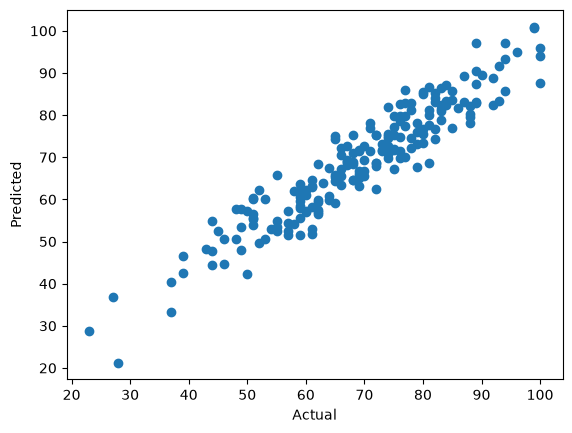

In [18]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")

<Axes: xlabel='math score'>

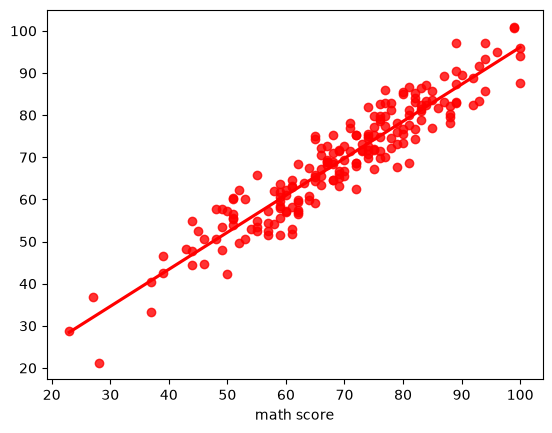

In [19]:
sns.regplot(x=y_test,y=y_pred,ci=None,color ='red')

In [20]:
pred_df = pd.DataFrame({'Actual Value':y_test, 'Predicted Value':y_pred, 'Difference':y_test-y_pred})
pred_df

,Actual Value,Predicted Value,Difference
521,67,68.184361,-1.184361
737,78,81.306396,-3.306396
740,39,42.646078,-3.646078
660,70,69.310052,0.689948
411,90,89.600674,0.399326
...,...,...,...
408,100,87.589090,12.410910
332,66,70.499739,-4.499739
208,66,63.421025,2.578975
613,68,64.643819,3.356181


In [24]:
import joblib
joblib.dump(lin_model, "lin_model.pkl")

['lin_model.pkl']